In [24]:
import pandas as pd
import json

# Load raw dataset
df = pd.read_csv('juanmart_raw_sales.csv')

# Preview first few rows
df.head()

,transaction_id,cust_name,region,order_date,amount_paid,status
0,1001,Juan Dela Cruz,NCR,2026-07-01,1500.50,Completed
1,1002,Maria Santos,Metro Manila,2026/07/02,2400.00,Completed
2,1003,NaN,ncr,2026-07-02,450.00,Cancelled
3,1004,Pedro Penduko,CALABARZON,2026/07/03,NaN,Completed
4,1005,Ana Roces,calabarzon,2026-07-04,3100.25,Completed


In [25]:
# Check total rows, columns, and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  12 non-null     int64  
 1   cust_name       10 non-null     str    
 2   region          12 non-null     str    
 3   order_date      12 non-null     str    
 4   amount_paid     10 non-null     float64
 5   status          12 non-null     str    
dtypes: float64(1), int64(1), str(4)
memory usage: 1.1 KB


In [26]:
# Count missing values per column
missing_summary = df.isnull().sum()

print('Missing Values Summary:')
print(missing_summary)

# Find duplicate rows
duplicates = df[df.duplicated(keep=False)]
duplicate_count = df.duplicated().sum()

print(f'\nTotal duplicate rows: {duplicate_count}')
print('\nDuplicate Rows:')
display(duplicates)

Missing Values Summary:
transaction_id    0
cust_name         2
region            0
order_date        0
amount_paid       2
status            0
dtype: int64

Total duplicate rows: 2

Duplicate Rows:


,transaction_id,cust_name,region,order_date,amount_paid,status
0,1001,Juan Dela Cruz,NCR,2026-07-01,1500.50,Completed
4,1005,Ana Roces,calabarzon,2026-07-04,3100.25,Completed
5,1001,Juan Dela Cruz,NCR,2026-07-01,1500.50,Completed
9,1005,Ana Roces,calabarzon,2026-07-04,3100.25,Completed


In [27]:
# Check Region values (Inconsistent casing and naming)
print("--- Region Value Counts ---")
region_counts = df['region'].value_counts(dropna=False)
print(region_counts)

print("\n--- Status Value Counts ---")
status_counts = df['status'].value_counts(dropna=False)
print(status_counts)

--- Region Value Counts ---
region
NCR             3
Metro Manila    2
ncr             2
CALABARZON      2
calabarzon      2
Region IV-A     1
Name: count, dtype: int64

--- Status Value Counts ---
status
Completed    9
Cancelled    2
Returned     1
Name: count, dtype: int64


In [28]:
# Summary statistics for numeric values
df.describe()

,transaction_id,amount_paid
count,12.000000,10.0000
mean,1005.083333,2095.2250
std,3.028901,1348.8760
min,1001.000000,450.0000
25%,1002.750000,1275.1250
50%,1005.000000,1675.2500
75%,1007.250000,2925.1875
max,1010.000000,5000.0000


In [29]:
# Generate Metadata Anomaly & Null/Outlier Profiling Report
health_report = {
    "dataset_metadata": {
        "total_raw_rows": len(df),
        "total_columns": len(df.columns),
        "columns": list(df.columns)
    },
    "data_quality_issues": {
        "duplicate_rows": int(duplicate_count),
        "missing_values": missing_summary.to_dict(),
        "inconsistent_regions": region_counts.to_dict(),
        "order_statuses": status_counts.to_dict()
    }
}

# Save to JSON file as required by Lab 1.1 Deliverables
with open('juanmart_health_report.json', 'w') as f:
    json.dump(health_report, f, indent=4)

print("Diagnostic profiling complete. Exported findings to 'juanmart_health_report.json'.")

Diagnostic profiling complete. Exported findings to 'juanmart_health_report.json'.


C:\Users\Brent\AppData\Local\Temp\ipykernel_33436\2225671857.py:46: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot(amounts, vert=False, patch_artist=True, widths=0.35, boxprops=dict(facecolor=okabe_ito[4], color=accent_color), medianprops=dict(color='white', linewidth=2), whiskerprops=dict(color=accent_color), capprops=dict(color=accent_color), flierprops=dict(marker='o', markerfacecolor=alert_color, markeredgecolor='none', markersize=5))


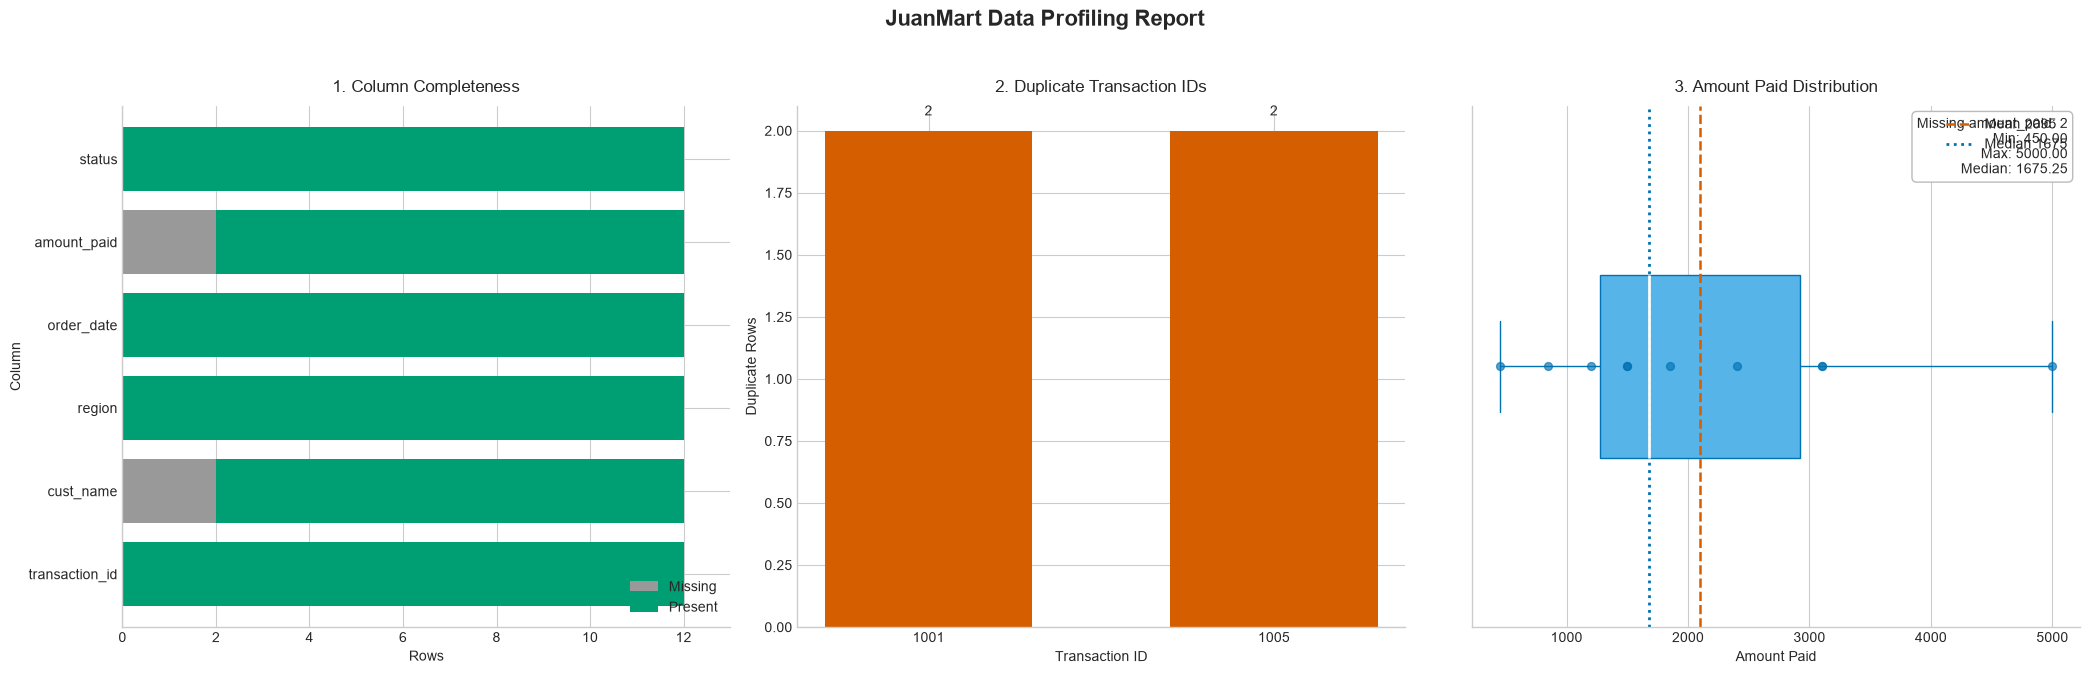

In [30]:
import matplotlib.pyplot as plt

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    pass

okabe_ito = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#F0E442', '#CC79A7', '#999999']
missing_color = okabe_ito[7]
present_color = okabe_ito[2]
accent_color = okabe_ito[0]
alert_color = okabe_ito[3]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

# 1) Column completeness
completeness = pd.DataFrame({
    'Missing': df.isna().sum(),
    'Present': df.notna().sum()
}).loc[['transaction_id', 'cust_name', 'region', 'order_date', 'amount_paid', 'status']]
completeness.plot(kind='barh', stacked=True, ax=axes[0], color=[missing_color, present_color], width=0.78)
axes[0].set_title('1. Column Completeness', pad=10)
axes[0].set_xlabel('Rows')
axes[0].set_ylabel('Column')
axes[0].legend(loc='lower right', frameon=False)
axes[0].set_xlim(0, len(df) + 1)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# 2) Duplicate transaction IDs
duplicate_ids = df.loc[df.duplicated(subset=['transaction_id'], keep=False), 'transaction_id'].value_counts().sort_index()
if not duplicate_ids.empty:
    axes[1].bar(duplicate_ids.index.astype(str), duplicate_ids.values, color=alert_color, edgecolor='none', width=0.6)
    for index, value in enumerate(duplicate_ids.values):
        axes[1].text(index, value + 0.05, str(value), ha='center', va='bottom', fontsize=10)
else:
    axes[1].text(0.5, 0.5, 'No duplicate IDs detected', ha='center', va='center', transform=axes[1].transAxes, fontsize=12)
axes[1].set_title('2. Duplicate Transaction IDs', pad=10)
axes[1].set_xlabel('Transaction ID')
axes[1].set_ylabel('Duplicate Rows')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# 3) Amount distribution
amounts = df['amount_paid'].dropna()
axes[2].boxplot(amounts, vert=False, patch_artist=True, widths=0.35, boxprops=dict(facecolor=okabe_ito[4], color=accent_color), medianprops=dict(color='white', linewidth=2), whiskerprops=dict(color=accent_color), capprops=dict(color=accent_color), flierprops=dict(marker='o', markerfacecolor=alert_color, markeredgecolor='none', markersize=5))
axes[2].scatter(amounts, [1] * len(amounts), color=accent_color, alpha=0.65, s=32, zorder=3)
axes[2].axvline(amounts.mean(), color=alert_color, linestyle='--', linewidth=1.8, label=f'Mean {amounts.mean():.0f}')
axes[2].axvline(amounts.median(), color=accent_color, linestyle=':', linewidth=2, label=f'Median {amounts.median():.0f}')
axes[2].set_title('3. Amount Paid Distribution', pad=10)
axes[2].set_xlabel('Amount Paid')
axes[2].set_yticks([])
axes[2].legend(frameon=False, loc='upper right')
summary_text = f"Missing amount_paid: {df['amount_paid'].isna().sum()}\nMin: {amounts.min():.2f}\nMax: {amounts.max():.2f}\nMedian: {amounts.median():.2f}"
axes[2].text(0.98, 0.98, summary_text, transform=axes[2].transAxes, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='#BBBBBB'))
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

plt.suptitle('JuanMart Data Profiling Report', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()